# Homework 8: Ordinary differential equations

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2024)  
**This homework assignment is due November 5, 2025, at 8 am.**   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Third-order Runge-Kutta Method

This exercise aims to find a Runge-Kutta algorithm of third order to solve the differential equation

$$ y^\prime(x) = F(x,y)$$

where $F(x,y)$ is at least three times differentiable with respect to the variables $x$ and $y$. 


a) Given the solution $y_n$ at $x_n$, the solution at point $x_{n+1} = x_n + h$ is expressed as

$$ y_{n+1} = y_n + \alpha_0 k_0 + \alpha_1 k_1 + \alpha_2 k_2 + O(h^4) $$

with

\begin{align}
k_0 &= hF(x_n,y_n) \\
k_1 &= hF(x_n + \mu_1 h,y_n + \lambda_1 k_0) \\
k_2 &= hF(x_n + \mu_2 h,y_n + \lambda_2 k_1)
\end{align}

There are 7 free parameters: $\alpha_0,\alpha_1,\alpha_2,\mu_1,\mu_2,\lambda_1,\lambda_2$. Just as for the second-order Runge-Kutta algorithm, expand the expression for $y_{n+1}$ into a Taylor series up to the third order in $h$ and determine the free parameters by matching them order-by-order to the Taylor expansion of the differential equation itself. 

b) Write a `Python` program to test your result in a) with the test case $F(x,y) = y$. Verify the order of the algorithm using your `Python` program.

[Question 1 PartA.](https://drive.google.com/file/d/1XJhom6g6yl-2DwZNpWa_Dr05W19PRdah/view?usp=sharing)

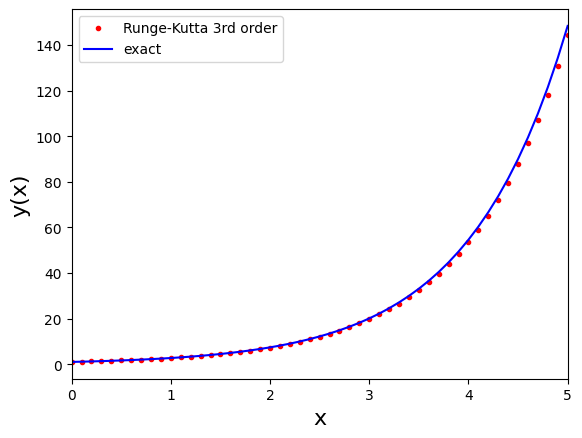

actual error (N = 10): 5.77440e+01
actual error (N = 100): 1.07824e+00
actual error (N = 1000): 1.12840e-02
actual error (N = 10000): 1.13318e-04
actual error (N = 100000): 1.13292e-06


In [20]:
#Q1 Part B.) Runge-Kutta Test Case 

import numpy as np
import matplotlib.pyplot as plt

#Runge-Kutte Method
def rk3(f,y0,x0,xe,N):
    h = (xe-x0)/N
    solution = [y0]
    x_s = [x0]
    x = x0
    y = y0
    for i in range(N):
        k0 = h*f(x,y)
        k1 = h*f(x + h, y +  (8.0/3.0)*k0)
        k2 = h*f(x + 2.0*h, y + (-1.0/3.0)*k1)
        y += (0.25*k0  + 0.25*k1 + 0.5*k2)
        x += h
        solution.append(y)
        x_s.append(x)
    return x_s, solution


#Boundary conditions 
x0 = 0.0 
y0 = 1.0 
xe = 5.0 
N = 50 


def f(x,y): 
    return (y)


#Solution Function 
def soln(x): 
    return (np.exp(x)) 

x_p, y_p = rk3(f, y0, x0, xe, N) 



plt.plot(x_p, y_p, "r.", label = "Runge-Kutta 3rd order")
plt.plot(x_p, soln(x_p), "b-", label = "exact")
plt.xlabel("x", fontsize = 16)
plt.ylabel("y(x)", fontsize = 16)
plt.xlim(x0, xe)
plt.legend()
plt.show()


for N in (10, 100, 1000, 10000, 100000):
    x_p, y_p = rk3(f, y0, x0, xe, N)
    error = (abs(y_p[N] - soln(x_p[N])))
    print(f"actual error (N = {N}): {error:1.5e}")



## Cometary orbits

Many comets travel in highly elongated orbits around the Sun. For much of their lives, they are far out in the solar system, moving very slowly, but on rare occasions, their orbit brings them close to the Sun for a fly-by, and, for a short period of time, they move very fast.

This is a classic example of a system for which an adaptive step size method is useful. For the large periods of time when the comet is moving slowly, we can use long time steps so that the program runs quickly, but short time steps are crucial in the short but fast-moving period close to the Sun.

The differential equation obeyed by a comet is straightforward to derive. The force between the Sun, with mass $M=1.9891\cdot 10^{30}kg$ at the origin, and a comet of mass $m$ with position vector $\vec{r}$ is $GMm/r^2$ in direction $-\vec{r}/r$ (i.e., the direction towards the Sun), where $G=6.6743 \cdot 10^{-11}m^3kg^{-1}s^{-2}$. Newton's second law dictates that

$$
m {d^2\vec{r}\over dt^2} = -\biggl({GMm\over r^2}\biggr)\,{\vec{r}\over r}.
$$

Canceling the~$m$ and taking the $x$ component, we have

$$
{d^2 x\over dt^2} = -GM {x\over r^3}\,,
$$

and similarly for the other two coordinates. We can, however, ignore one of the coordinates because the comet stays in a single plane as it orbits. If we orient our axes so that this plane is perpendicular to the~$z$-axis, we can ignore the $z$ coordinate, and we are left with just two second-order equations to solve:

$$
{d^2 x\over dt^2} = -GM {x\over r^3}\,, \qquad
{d^2 y\over dt^2} = -GM {y\over r^3}\,,
$$

a) Turn these two second-order equations into four first-order equations.
   
b) Write a `Python` program to solve your equations using the fourth-order Runge Kutta method with a **fixed** step size. As an initial condition, take a comet at coordinates $x=4$ billion kilometers and $y=0$ (somewhere out around Neptune's orbit) with initial velocity $v_x=0$ and $v_y = 500 m/s$. Make a figure that shows the comet's trajectory (i.e., a plot of $y$ against $x$).

Choose a fixed step size $h$ that allows you to accurately calculate at least two complete orbits of the comet. Since orbits are periodic, a good indicator for accurate calculations is that successive orbits of the comet lie on top of one another on your plot. If they do not, you need a smaller value of $h$. Give a short description of your findings. What value of $h$ did you use? What did you observe in your simulation? How long did the calculation take?

c) Use a fourth-order Runge-Kutta algorithm with **adaptive** step size to solve the problem above with the same initial conditions. Set a target accuracy of $\rho=1{\rm km/year}$ in the comet's position and plot the trajectory again. What do you observe? How do the speed, accuracy, and step size of the calculation compare with those obtained in part (b)?

(Question 2 Part b)[https://drive.google.com/file/d/1JOfyCLBQFWxB0m7x6B9AbcopFj3aWAeJ/view?usp=sharing]



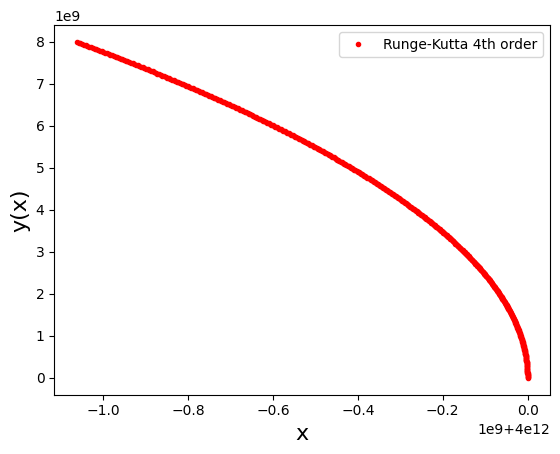

In [54]:
#Q2 Cometary Orbits Part B.) 
import numpy as np
import matplotlib.pyplot as plt

#initial conditions 
t0 = 0.0 
x0 = 4e12 
y0 = 0.0 
v_x_0 = 0.0 
v_y_0 = 500.0 
te = 1.6e7
N = 500
M = 1.9891e30 
G = 6.6743e-11


#acceleration function 
def acc(x,y): 
    r = np.sqrt(x**2 + y**2) 
    ax = -G*M*x/(r**3)
    ay = -G*M*y/(r**3)
    return ax, ay 

def f(s, t): 
    x, y, vx, vy = s 
    ax, ay = acc(x,y) 
    return np.array([vx, vy, ax, ay], dtype = float)



#rk4 (This is universal to where all 4 can be used) 
def rk4(f,x0,t0,te,N):
    h = (te-t0)/N
    x = np.array(x0, dtype=float)
    t = t0
    solution = [x.copy()]
    times = [t]
    for i in range(N):
        k1 = h*f(x,t)
        k2 = h*f(x+0.5*k1,t+0.5*h)
        k3 = h*f(x+0.5*k2,t+0.5*h)
        k4 = h*f(x+k3,t+h)
        x += (k1+2*k2+2*k3+k4)/6
        t += h
        solution.append(x.copy())
        times.append(t)
        
    return np.array(times), np.array(solution)

#Odes defined and arrays
s0 = np.array([x0, y0, v_x_0, v_y_0], dtype = float) 
T, S = rk4(f, s0, t0, te, N) 
X = S[:,0] 
Y = S[:,1] 
VX  = S[:,2] 
VY = S[:,3] 



plt.plot(X, Y, "r.", label = "Runge-Kutta 4th order")
plt.xlabel("x", fontsize = 16)
plt.ylabel("y(x)", fontsize = 16)
plt.legend()
plt.show()